# Madrid supervised pretraining → Amsterdam fine-tuning

This experiment tests supervised source representations with **25 Amsterdam labels per class**, five spatial folds and three matched sampling repetitions. Settings were fixed before outer evaluation. These are previously used development folds, not an independent test.

Madrid labels are harmonized to the Amsterdam year boundaries **1945, 1984, 2004, 2024** using supplied Madrid construction years. Years never enter the predictors. The Amsterdam labels and sampling budget remain unchanged. See [the report](../../docs/TORCH_TRANSFER.md) for interpretation and sources.


In [ ]:
from scripts.torch_transfer import CONFIG, TransferMLP, verify
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import json
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'pyproject.toml').exists():
    if ROOT == ROOT.parent:
        raise RuntimeError('Run inside the repository')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
OUT = ROOT / 'data/torch_transfer'
verify()

Verified 120 run scores, 623,808 probability rows, 15 exact budgets, source preprocessing and encoder weights.


## 1. Pretrain on Madrid

The network is 54 → 64 → 32 → 4, with ReLU and dropout 0.2. Preprocessing fits only on Madrid folds 1–4. Madrid fold 0 is spatially disjoint and selects the source checkpoint by macro F1. Class-weighted cross entropy addresses source imbalance. No Amsterdam features or labels enter source pretraining.


TransferMLP(
  (encoder): Sequential(
    (0): Linear(in_features=54, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
  )
  (head): Linear(in_features=32, out_features=4, bias=True)
)
{'seed': 42, 'hidden': [64, 32], 'dropout': 0.2, 'target_boundaries': [1945, 1984, 2004, 2024], 'source_checkpoint_fold': 0, 'source_max_epochs': 80, 'source_patience': 12, 'source_batch_size': 512, 'source_learning_rate': 0.001, 'target_epochs': 300, 'head_learning_rate': 0.001, 'encoder_learning_rate': 0.0001, 'weight_decay': 0.01, 'folds': 5, 'repetitions': 3, 'labels_per_class': 25, 'rf_blend_weight': 0.5, 'device': 'cpu'}


n_fit                                            61010
n_checkpoint                                     15253
best_epoch                                          52
checkpoint_macro_f1                           0.602785
relabeled_locations                               8450
fit_class_counts           [4310, 28447, 14937, 13316]
checkpoint_class_counts       [1034, 7155, 3735, 3329]
dtype: object

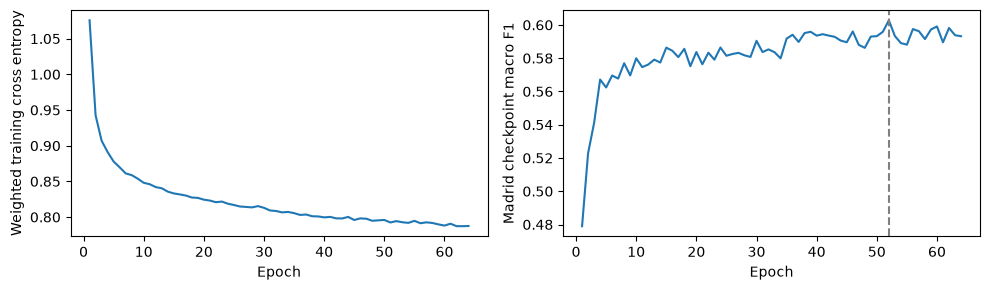

In [ ]:
print(TransferMLP())
print(CONFIG)
manifest = json.loads((OUT / 'experiment.json').read_text())
display(pd.Series(manifest['pretraining']))
history = pd.read_csv(OUT / 'source_history.csv')
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(history.epoch, history.training_loss)
axes[0].set(xlabel='Epoch', ylabel='Weighted training cross entropy')
axes[1].plot(history.epoch, history.checkpoint_macro_f1)
axes[1].axvline(manifest['pretraining']['best_epoch'],
                color='gray', linestyle='--')
axes[1].set(xlabel='Epoch', ylabel='Madrid checkpoint macro F1')
fig.tight_layout()
plt.show()

## 2. Adapt using exactly 100 Amsterdam labels

A fresh classifier head is initialized identically for four controls:

- **Frozen encoder:** transfer hidden layers; train only the new head. Encoder dropout is disabled.
- **Fine-tuned:** transfer hidden layers; train encoder at 0.0001 and head at 0.001.
- **Scratch:** initialize the whole network randomly; train everything at 0.001.
- **Scratch, matched LR:** random initialization with the same differential learning rates as fine-tuning. This comparison isolates initialization under the fixed training procedure.

All new neural methods share the Madrid-fitted scaler, the same architecture, 300 fixed full-batch adaptation epochs and AdamW weight decay 0.01. Target labels never select settings or epochs. The source-only model retains its Madrid-trained head. A fixed 50/50 fine-tuned/RF blend is an additional comparison.


,macro_f1,weighted_f1,accuracy,balanced_accuracy,severe_error_rate,macro_f1_fold_sd,delta_vs_rf,delta_vs_raw_mlp
method,,,,,,,,
rf_fine_tuned_blend,0.5679,0.5769,0.5767,0.5858,0.0953,0.0158,0.0185,0.0232
scratch,0.5534,0.5634,0.5642,0.5760,0.1107,0.0199,0.0040,0.0087
original_blend,0.5494,0.5636,0.5652,0.5559,0.0863,0.0258,0.0000,0.0047
raw_mlp,0.5447,0.5579,0.5576,0.5654,0.1101,0.0254,-0.0047,0.0000
fine_tuned,0.5353,0.5410,0.5453,0.5622,0.1123,0.0172,-0.0141,-0.0094
scratch_matched_lr,0.4873,0.4968,0.5044,0.5167,0.1421,0.0346,-0.0621,-0.0574
frozen_encoder,0.4587,0.4605,0.4706,0.4871,0.1381,0.0088,-0.0907,-0.0860
source_only,0.3973,0.3995,0.4332,0.4105,0.1111,0.0161,-0.1521,-0.1475


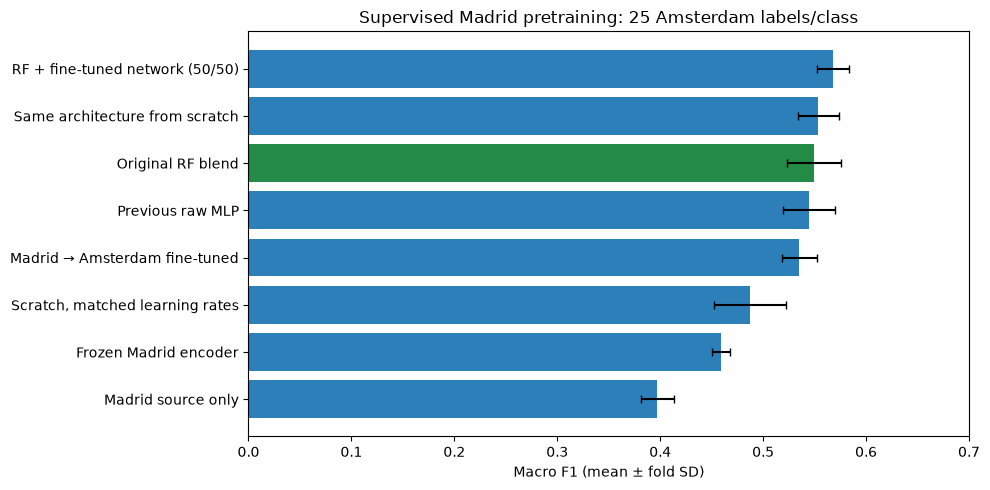

In [ ]:
summary = pd.read_csv(OUT / 'summary.csv', index_col='method')
display(summary.sort_values('macro_f1', ascending=False).round(4))
labels = {'original_blend': 'Original RF blend', 'raw_mlp': 'Previous raw MLP',
          'source_only': 'Madrid source only', 'frozen_encoder': 'Frozen Madrid encoder',
          'fine_tuned': 'Madrid → Amsterdam fine-tuned', 'scratch': 'Same architecture from scratch',
          'scratch_matched_lr': 'Scratch, matched learning rates',
          'rf_fine_tuned_blend': 'RF + fine-tuned network (50/50)'}
ordered = summary.sort_values('macro_f1')
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh([labels[m] for m in ordered.index], ordered.macro_f1,
        xerr=ordered.macro_f1_fold_sd, capsize=3,
        color=['#238b45' if m == 'original_blend' else '#2c7fb8' for m in ordered.index])
ax.set(xlim=(0, .7), xlabel='Macro F1 (mean ± fold SD)',
       title='Supervised Madrid pretraining: 25 Amsterdam labels/class')
fig.tight_layout()
fig.savefig(ROOT / 'docs/assets/torch_transfer.png', dpi=160)
plt.show()

## 3. Inspect class-level performance and paired fold differences

Repetitions average within folds first. Fold SD is descriptive, not a confidence interval. The three repetitions share a single pretrained Madrid model and source-only predictions are repeated for alignment, not independent retraining. The RF uses all Madrid source labels with the original city-specific boundaries; this experiment uses harmonized labels and holds out a source checkpoint fold.


In [ ]:
classes = pd.read_csv(OUT / 'class_metrics.csv')
display(classes.groupby(['method', 'fold', 'age_class'])[['precision', 'recall', 'f1']].mean()
        .groupby(['method', 'age_class']).mean().round(4))
display(pd.read_csv(OUT / 'paired_fold_scores.csv').round(4))

precision  recall      f1
method              age_class                           
fine_tuned          1             0.5779  0.7049  0.6332
                    2             0.5852  0.4239  0.4884
                    3             0.5891  0.4876  0.5268
                    4             0.4173  0.6324  0.4927
frozen_encoder      1             0.5095  0.6605  0.5709
                    2             0.4849  0.3608  0.4077
                    3             0.5217  0.3594  0.4128
                    4             0.3746  0.5675  0.4435
original_blend      1             0.7228  0.5687  0.6337
                    2             0.5169  0.6836  0.5872
                    3             0.6134  0.4075  0.4847
                    4             0.4487  0.5639  0.4919
raw_mlp             1             0.6230  0.6617  0.6404
                    2             0.5796  0.4914  0.5302
                    3             0.5778  0.5097  0.5396
                    4             0.3901  0.5988  0.4687
rf_fine_tuned_blend 1             0.6356  0.6713  0.6514
                    2             0.5771  0.5423  0.5571
                    3             0.6244  0.4877  0.5437
                    4             0.4473  0.6420  0.5192
scratch             1             0.6163  0.6663  0.6387
                    2             0.5813  0.4894  0.5298
                    3             0.6008  0.5197  0.5533
                    4             0.4082  0.6286  0.4919
scratch_matched_lr  1             0.5415  0.7161  0.6118
                    2             0.5811  0.3596  0.4412
                    3             0.5352  0.4324  0.4707
                    4             0.3491  0.5589  0.4256
source_only         1             0.4835  0.3973  0.4354
                    2             0.3890  0.7086  0.5022
                    3             0.6568  0.1225  0.2056
                    4             0.4859  0.4136  0.4458

,fold,fine_tuned,frozen_encoder,original_blend,raw_mlp,rf_fine_tuned_blend,scratch,scratch_matched_lr,source_only,fine_tuned_minus_frozen,fine_tuned_minus_scratch,fine_tuned_minus_scratch_matched_lr,fine_tuned_minus_rf
0,0,0.5300,0.4522,0.5328,0.5454,0.5607,0.5508,0.5073,0.4222,0.0777,-0.0208,0.0227,-0.0028
1,1,0.5190,0.4564,0.5633,0.5587,0.5634,0.5563,0.4979,0.4021,0.0626,-0.0372,0.0212,-0.0443
2,2,0.5322,0.4666,0.5515,0.5416,0.5620,0.5581,0.4507,0.3936,0.0656,-0.0259,0.0815,-0.0193
3,3,0.5646,0.4691,0.5828,0.5729,0.5958,0.5786,0.5286,0.3883,0.0955,-0.0140,0.0360,-0.0182
4,4,0.5305,0.4492,0.5166,0.5049,0.5575,0.5232,0.4521,0.3800,0.0814,0.0073,0.0784,0.0140


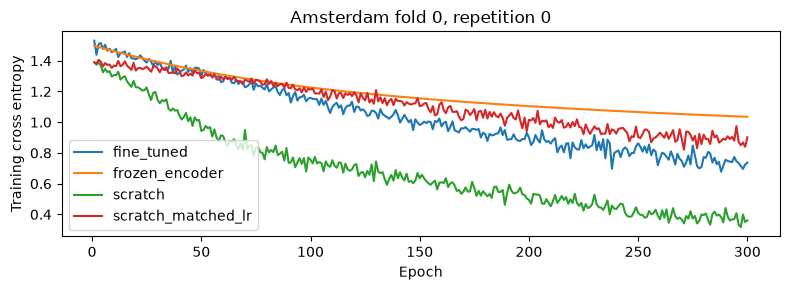

In [ ]:
history = pd.read_csv(OUT / 'target_history.csv')
fig, ax = plt.subplots(figsize=(8, 3))
for method, frame in history.loc[history.fold.eq(0) & history.repetition.eq(0)].groupby('method'):
    ax.plot(frame.epoch, frame.training_loss, label=method)
ax.set(xlabel='Epoch', ylabel='Training cross entropy',
       title='Amsterdam fold 0, repetition 0')
ax.legend()
fig.tight_layout()
plt.show()

## Reproduce

```bash
uv sync --locked --extra deep-learning
uv run --extra deep-learning python -m scripts.torch_transfer
uv run --extra deep-learning python -m scripts.torch_transfer --verify
```

Default notebook cells inspect and verify artifacts without retraining. Prerequisites are the preprocessed city tables, baseline memberships and saved `torch_comparison` predictions. Exported weights are examples excluded from Amsterdam fold 0, not final production models. See `scripts/torch_transfer.py` for the complete training loop and parameter groups.


In [ ]:
best = summary.drop(index='source_only').macro_f1.idxmax()
fine = summary.loc['fine_tuned', 'macro_f1']
rf = summary.loc['original_blend', 'macro_f1']
scratch = summary.loc['scratch', 'macro_f1']
matched = summary.loc['scratch_matched_lr', 'macro_f1']
print(f'Fine-tuned macro F1: {fine:.4f}; RF: {rf:.4f}; delta: {fine-rf:+.4f}')
print(
    f'Fine-tuning vs scratch: {fine-scratch:+.4f}; vs matched-LR scratch: {fine-matched:+.4f}')
print(
    f'Highest observed adapted/control score: {best} ({summary.loc[best, "macro_f1"]:.4f})')

Fine-tuned macro F1: 0.5353; RF: 0.5494; delta: -0.0141
Fine-tuning vs scratch: -0.0181; vs matched-LR scratch: +0.0480
Highest observed adapted/control score: rf_fine_tuned_blend (0.5679)


## Conclusion

Read the measured conclusion in [the experiment report](../../docs/TORCH_TRANSFER.md). These fixed procedures test whether supervised source pretraining helps under the stated settings. They do not establish an independent competition-test gain. Avoid choosing a new blend weight, epoch count or architecture from these outer results; a subsequent tuned procedure needs inner spatial selection and ultimately an untouched geographic test.
